# 01 Clean the data and define churn

Load the UCI Online Retail II transactions, apply the cleaning rules, and turn churn into a label we can predict. At each cutoff date, a customer who bought in the previous year has churned if they make no purchase in the next 90 days.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_clean
from src.labels import build_snapshots, split_cutoffs, valid_cutoffs

## Cleaning

Rules, in order: drop rows without a customer ID, drop exact duplicates, drop December 2011 (the file stops on 9 December), drop non-product codes such as postage and fees, and drop zero or negative prices. Cancellations (invoices starting with "C") are kept separately.

In [2]:
data = load_clean()
purchases = data.purchases
data.report

,step,rows,removed
0,raw rows,1067371,0
1,drop missing customer ID,824364,243007
2,drop exact duplicates,797885,26479
3,drop on/after 2011-12-01,780502,17383
4,drop non-product codes,776915,3587
5,drop price <= 0,776855,60
6,-> purchases,759615,0
7,-> cancellations,17240,0


Most of the loss is the first step: about 23% of lines have no customer ID and can't be linked to a customer. Results describe identified customers only.

## Churn

Cutoff dates are the first of each month. Each needs a year of history before it and 90 days after it, which leaves 10 cutoffs. Models learn from the first 5 and are tested on the last 3. The 2 in between are skipped so training and testing never overlap.

In [3]:
cutoffs = valid_cutoffs(90)
train_cuts, test_cuts = split_cutoffs(cutoffs, horizon_days=90, n_test=3)
snapshots = build_snapshots(purchases, cutoffs, horizon_days=90)

print(f"{len(snapshots):,} snapshots of {snapshots['customer_id'].nunique():,} customers")
print(f"churn rate: training {snapshots[snapshots['cutoff'].isin(train_cuts)]['churn'].mean():.0%}, "
      f"test {snapshots[snapshots['cutoff'].isin(test_cuts)]['churn'].mean():.0%}")

42,850 snapshots of 5,224 customers
churn rate: training 65%, test 56%


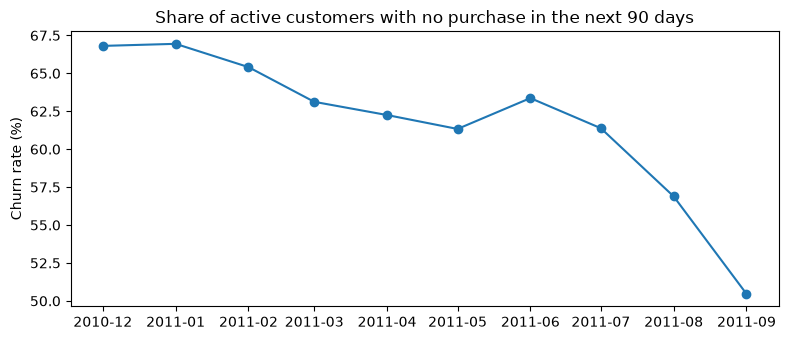

In [4]:
rates = snapshots.groupby("cutoff")["churn"].mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(rates.index, rates * 100, marker="o")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Share of active customers with no purchase in the next 90 days")
fig.tight_layout()
fig.savefig(ROOT / "reports" / "figures" / "churn_rate.png")

## Findings

Churn is common: 50% to 67% of active customers make no purchase in the next 90 days, depending on the month. It is lower for the test months (56%) than the training months (65%) because those 90 days lead into the holiday season, when shops restock.